# Tugas 1 – Estimasi Titik dan Interval
**Pertemuan 9** | Kampus Merdeka

Nama: ........  NIM: ........

**Soal**
1. Carilah data sebanyak 100 sampel.
2. (a) Hitung estimasi titik dan interval menggunakan distribusi Z, tingkat kesalahan 5%.
3. (b) Resampling dengan jackknife dan bootstrapping (1000 iterasi), hitung rata-rata hasil resampling.

## 1. Import library & data (100 sampel)
Data: kolom `target` (ukuran progresi penyakit diabetes setelah 1 tahun) dari dataset *Diabetes* bawaan `scikit-learn`. Dari 442 pasien diambil **100 sampel acak** (`random_state=42`).

> Ingin pakai data sendiri? Ganti `data` dengan array 100 nilai dari CSV Anda.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_diabetes

rng = np.random.default_rng(42)
full = load_diabetes(as_frame=True).frame['target']
data = full.sample(n=100, random_state=42).to_numpy()

print("Jumlah sampel:", len(data))
pd.Series(data, name="target").describe()

Jumlah sampel: 100


count    100.000000
mean     146.840000
std       74.430867
min       37.000000
25%       88.500000
50%      132.000000
75%      202.000000
max      310.000000
Name: target, dtype: float64

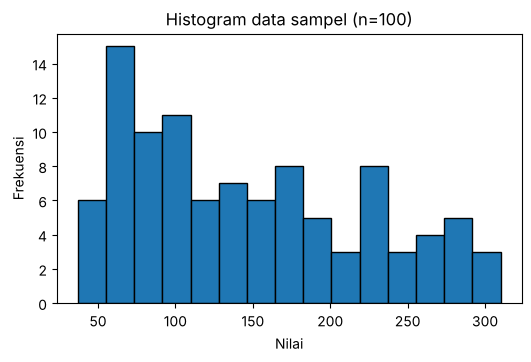

In [2]:
plt.figure(figsize=(6,3.5))
plt.hist(data, bins=15, edgecolor='k')
plt.title("Histogram data sampel (n=100)"); plt.xlabel("Nilai"); plt.ylabel("Frekuensi")
plt.show()

## 2. (a) Estimasi titik & interval – distribusi Z (α = 5%)

Estimasi titik: $\bar{x}$

Estimasi interval: $\bar{x} \pm Z_{\alpha/2}\,\dfrac{\sigma}{\sqrt{n}}$

Karena σ populasi tidak diketahui dan n = 100 (besar), σ didekati dengan simpangan baku sampel *s*.

In [3]:
n = len(data)
alpha = 0.05
x_bar = data.mean()
s = data.std(ddof=1)
se = s/np.sqrt(n)
z = stats.norm.ppf(1 - alpha/2)
moe = z*se
ci_z = (x_bar - moe, x_bar + moe)

print(f"Estimasi titik (rata-rata)  : {x_bar:.4f}")
print(f"Simpangan baku sampel (s)   : {s:.4f}")
print(f"Standard error              : {se:.4f}")
print(f"Z kritis (alpha/2 = 0.025)  : {z:.4f}")
print(f"Margin of error             : {moe:.4f}")
print(f"Interval kepercayaan 95%    : ({ci_z[0]:.4f}, {ci_z[1]:.4f})")

Estimasi titik (rata-rata)  : 146.8400
Simpangan baku sampel (s)   : 74.4309
Standard error              : 7.4431
Z kritis (alpha/2 = 0.025)  : 1.9600
Margin of error             : 14.5882
Interval kepercayaan 95%    : (132.2518, 161.4282)


**Interpretasi:** Dengan tingkat kesalahan 5%, kita yakin 95% bahwa rata-rata populasi berada di dalam interval di atas.

## 3. (b) Resampling
### 3.1 Jackknife (leave-one-out)

In [4]:
def jackknife(func, data):
    data = np.asarray(data); n = len(data)
    thetas = np.array([func(np.delete(data, i)) for i in range(n)])
    theta_hat = func(data); theta_bar = thetas.mean()
    return {'theta_hat': theta_hat,
            'theta_bar': theta_bar,                       # rata-rata hasil resampling
            'bias': (n-1)*(theta_bar-theta_hat),
            'se': np.sqrt((n-1)/n*np.sum((thetas-theta_bar)**2)),
            'thetas': thetas}

jk = jackknife(np.mean, data)
ci_jk = (jk['theta_bar']-z*jk['se'], jk['theta_bar']+z*jk['se'])
print(f"Jumlah resample jackknife       : {len(jk['thetas'])}")
print(f"Rata-rata hasil jackknife       : {jk['theta_bar']:.4f}")
print(f"Estimasi bias                   : {jk['bias']:.6f}")
print(f"Standard error jackknife        : {jk['se']:.4f}")
print(f"CI 95% jackknife (normal)       : ({ci_jk[0]:.4f}, {ci_jk[1]:.4f})")

Jumlah resample jackknife       : 100
Rata-rata hasil jackknife       : 146.8400
Estimasi bias                   : 0.000000
Standard error jackknife        : 7.4431
CI 95% jackknife (normal)       : (132.2518, 161.4282)


### 3.2 Bootstrapping (1000 iterasi)

In [5]:
B = 1000
boot_means = np.array([rng.choice(data, size=n, replace=True).mean() for _ in range(B)])

boot_mean = boot_means.mean()
boot_se = boot_means.std(ddof=1)
ci_boot = np.percentile(boot_means, [2.5, 97.5])
print(f"Jumlah iterasi bootstrap        : {B}")
print(f"Rata-rata hasil bootstrap       : {boot_mean:.4f}")
print(f"Standard error bootstrap        : {boot_se:.4f}")
print(f"CI 95% bootstrap (persentil)    : ({ci_boot[0]:.4f}, {ci_boot[1]:.4f})")

Jumlah iterasi bootstrap        : 1000
Rata-rata hasil bootstrap       : 147.0340
Standard error bootstrap        : 7.4662
CI 95% bootstrap (persentil)    : (132.9790, 161.9532)


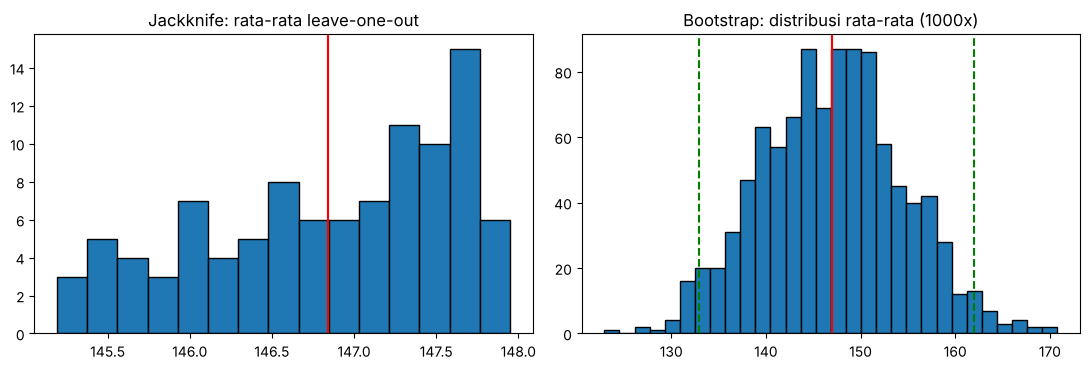

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11,3.8))
ax[0].hist(jk['thetas'], bins=15, edgecolor='k'); ax[0].axvline(jk['theta_bar'], color='r')
ax[0].set_title("Jackknife: rata-rata leave-one-out")
ax[1].hist(boot_means, bins=30, edgecolor='k'); ax[1].axvline(boot_mean, color='r')
ax[1].axvline(ci_boot[0], color='g', ls='--'); ax[1].axvline(ci_boot[1], color='g', ls='--')
ax[1].set_title("Bootstrap: distribusi rata-rata (1000x)")
plt.tight_layout(); plt.show()

## 4. Perbandingan hasil

In [7]:
pd.DataFrame({
    'Rata-rata': [x_bar, jk['theta_bar'], boot_mean],
    'Std. Error': [se, jk['se'], boot_se],
    'CI 95% bawah': [ci_z[0], ci_jk[0], ci_boot[0]],
    'CI 95% atas': [ci_z[1], ci_jk[1], ci_boot[1]],
}, index=['Distribusi Z', 'Jackknife', 'Bootstrap (B=1000)']).round(4)

,Rata-rata,Std. Error,CI 95% bawah,CI 95% atas
Distribusi Z,146.840,7.4431,132.2518,161.4282
Jackknife,146.840,7.4431,132.2518,161.4282
Bootstrap (B=1000),147.034,7.4662,132.9790,161.9532


## 5. Kesimpulan
- Estimasi titik rata-rata sampel dan interval 95% dari distribusi Z sudah dihitung pada bagian 2.
- Rata-rata hasil jackknife hampir identik dengan rata-rata sampel (bias sangat kecil), karena rata-rata adalah estimator tak bias.
- Rata-rata bootstrap (1000 iterasi) sangat dekat dengan rata-rata sampel; SE dan interval bootstrap mendekati hasil distribusi Z, sehingga ketiga metode konsisten.